# Task 1 – Supervised Fashion Classification

Train and evaluate the convolutional classifier using the cross-validation strategy defined for this project.

## Context
This notebook implements Task 1. The objective is to organise the main clothe collection by training a supervised classifier on the main classes train split and evaluating it on the main classes test split. Accuracy and balanced accuracy must be reported because the test set is imbalanced. Cross validation is used on five folds and aggregates the metrics to demonstrate consistent performance.

## Environment and packages

Run this notebook inside the project environment (see README for `uv` commands).

In [8]:
from pathlib import Path

import torch
from IPython.display import display
from sklearn.model_selection import KFold

from fashion_metric import build_HHD_model, train_transfer_model
from fashion_metric.data import build_all_datasets, build_classifier_dataloaders

In [9]:
DATASETS = build_all_datasets()
train_dataset = DATASETS["train_dataset"]
print(f"Train samples: {len(train_dataset):,}")

Train samples: 35,934


In [10]:
NUM_CLASSES = 39
BATCH_SIZE = 32
EPOCHS = 25
LR = 5e-5
KFOLDS = 5

config = {
    "model_fn": build_HHD_model,
    "lr": LR,
    "num_classes": NUM_CLASSES,
}


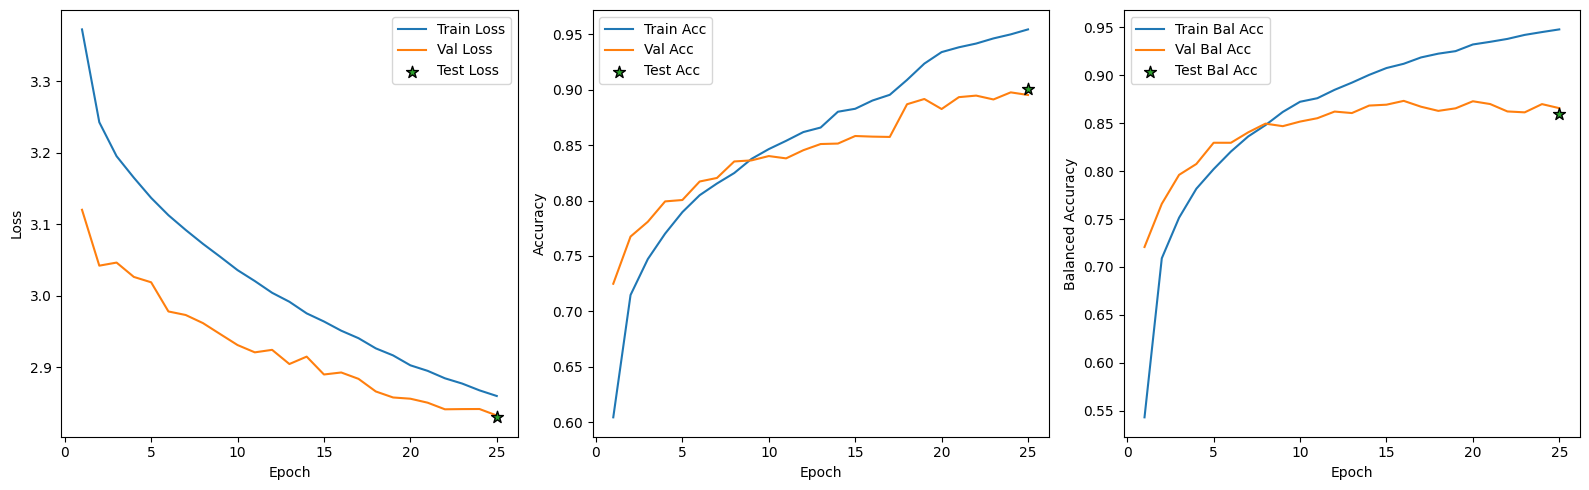


Metrics saved to output/build_HHD_model/fold5/metrics_fold5.json
Train → Loss: 2.8596, Acc: 0.9544, Balanced Acc: 0.9480
Val → Loss: 2.8322, Acc: 0.8952, Balanced Acc: 0.8658
Test → Loss: 2.8297, Acc: 0.9004, Balanced Acc: 0.8600


In [11]:
# Set to True to enable training
ENABLE_TRAINING = True
OUTPUT_DIR = Path("output/build_HHD_model")

if ENABLE_TRAINING:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    kfold = KFold(n_splits=KFOLDS, shuffle=True, random_state=42)
    for fold, (train_idx, val_idx) in enumerate(kfold.split(range(len(train_dataset))), start=1):
        print(f"Fold {fold}/{KFOLDS}")
        train_loader, val_loader, test_loader = build_classifier_dataloaders(
            train_idx=train_idx,
            val_idx=val_idx,
            batch_size=BATCH_SIZE,
        )
        fold_dir = OUTPUT_DIR / f"fold{fold}"
        train_transfer_model(
            config=config,
            model_name="build_HHD_model",
            train_loader=train_loader,
            val_loader=val_loader,
            test_loader=test_loader,
            epochs=EPOCHS,
            save_dir=fold_dir,
            fold=fold,
        )
else:
    print("Training is disabled. Set ENABLE_TRAINING = True to run the Task 1 experiment.")

In [12]:
import pandas as pd
cv_path = Path("output/build_HHD_model/crossval_metrics.csv")
if cv_path.exists():
    display(pd.read_csv(cv_path))
else:
    print("Run training to generate cross-validation metrics.")

,fold,test_loss,test_acc,test_bal_acc,val_loss,val_acc,val_bal_acc
0,1,2.833435,0.893841,0.860754,2.831432,0.898149,0.869351
1,2,2.844477,0.890836,0.859037,2.844162,0.893001,0.873630
2,3,2.842857,0.892339,0.851168,2.837278,0.896897,0.864188
3,4,2.839272,0.893841,0.847237,2.831228,0.899680,0.857156
4,5,2.828919,0.901853,0.863266,2.830066,0.900223,0.873975
